# Truncated against locally sparse estimation

We compare the two methods implemented here. `truncFLR` assumes the informative set is a
single interval and estimates its endpoint (Hall & Hooker, 2016); `fdaSP` lets it be any union
of intervals and induces the sparsity by an overlap group lasso (Stefanucci, Bernardi &
Canale, 2025). They solve overlapping but different problems, so the interesting question is
what each costs when its own assumption is right and when it is wrong.

We run both on two coefficient functions over 50 replications each: a single window, which is
`truncFLR`'s model, and a pair of disjoint windows, which is not.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from truncFLR import HH, HH_A, HH_dgp
from fdaSP import SBC

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

grid = np.linspace(0, 1, 301)
lambdas = np.linspace(0.0, 1.0, 250)[1:]
n_rep = 50

The first target is the one Hall & Hooker's model describes. We rescale a trading day to
$[0, 1]$ and suppose only the last quarter of it carries signal, so the cutoff is $u = 0.75$,
with $\beta$ rising smoothly from zero at $u$ to one at $t = 1$:

$$\beta(t) = \tfrac{1}{2}\left\{1 - \cos\left(\pi\,\frac{t - u}{1 - u}\right)\right\}
\mathbb{1}_{[u, 1]}(t).$$

$\beta$ meets the axis with zero derivative at $u$, so the boundary is smooth rather than a
jump, which is the harder of the two boundary types in the paper's Section 4. It also stays
genuinely non-zero across the window, at $0.10$ by $t = 0.8$ and $0.5$ by $t = 0.875$, so the
informative set really is $[0.75, 1]$ rather than a sliver at the right-hand end.

In [2]:
u, v = 0.75, 1.0


def beta_window(t, u=u, v=v):
    """Raised-cosine rise from beta(u) = 0 to beta(v) = 1, zero below u."""
    t = np.asarray(t, float)
    b = np.zeros_like(t)
    w = (t >= u) & (t <= v)
    b[w] = 0.5 * (1.0 - np.cos(np.pi * (t[w] - u) / (v - u)))
    return b


def beta_two_windows(t):
    """Two disjoint raised-cosine bumps, on [0.15, 0.35] and [0.75, 0.95]."""
    t = np.asarray(t, float)
    b = np.zeros_like(t)
    for lo, hi in [(0.15, 0.35), (0.75, 0.95)]:
        w = (t >= lo) & (t <= hi)
        b[w] = 0.5 * (1 - np.cos(2 * np.pi * (t[w] - lo) / (hi - lo)))
    return b


check = beta_window(np.array([u, 0.8, 0.875, 1.0]))
print(f"beta_window at u, 0.8, 0.875, 1.0 = {np.round(check, 4)}")

beta_window at u, 0.8, 0.875, 1.0 = [0.     0.0955 0.5    1.    ]


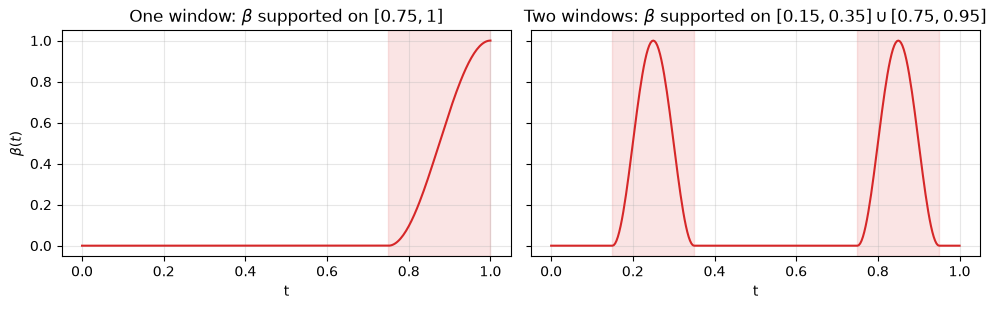

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
ax[0].plot(grid, beta_window(grid), color="C3")
ax[0].axvspan(u, v, color="C3", alpha=0.12)
ax[0].set_title(r"One window: $\beta$ supported on $[0.75, 1]$")
ax[1].plot(grid, beta_two_windows(grid), color="C3")
for lo, hi in [(0.15, 0.35), (0.75, 0.95)]:
    ax[1].axvspan(lo, hi, color="C3", alpha=0.12)
ax[1].set_title(r"Two windows: $\beta$ supported on $[0.15,0.35] \cup [0.75,0.95]$")
for a in ax:
    a.set_xlabel("t")
ax[0].set_ylabel(r"$\beta(t)$")
plt.tight_layout(); plt.show()

We generate each replication from the same i.i.d. curves both estimators were built for, fit
all three, and record the integrated squared error against the truth. `HH` is method B, `HH_A`
is method A, and `SBC` picks its own $\lambda$ by ten-fold cross-validation.

In [4]:
def one_replication(beta_fn, seed):
    """ISE of each method on one dataset, plus method A's endpoint and component count."""
    d = HH_dgp.sim_dataset(n=200, n_grid=len(grid), u=0.0, v=1.0, snr=20.0,
                           beta_fn=beta_fn, rng=seed)
    X, Y, beta_true = d["X"], d["Y"], d["b"]

    res_a = HH_A.fit_mirror(X, Y, grid, lambdas)
    out = {
        "HH method B": HH.fit_mirror(X, Y, grid, lambdas)["b_hat"],
        "HH method A": res_a["b_hat"],
        "SBC (OGL)": SBC.cv_fit(X, Y - Y.mean(), grid, n_basis=15, n_folds=10,
                                n_lambda=30, rng=seed)["beta"],
    }
    ise = {k: float(np.trapezoid((b - beta_true) ** 2, grid)) for k, b in out.items()}
    return ise, {"u_hat": res_a["u_hat"], "m_hat": res_a["m_hat"]}


METHODS = ["HH method B", "HH method A", "SBC (OGL)"]
results, diagnostics = {}, {}


def run_target(name, beta_fn):
    """Fit every method on `n_rep` datasets from `beta_fn`, recording each one's ISE."""
    acc = {m: [] for m in METHODS}
    diag = []
    for r in range(n_rep):
        ise, dg = one_replication(beta_fn, r)
        for m, val in ise.items():
            acc[m].append(val)
        diag.append(dg)
        if (r + 1) % 10 == 0:
            print(f"  {name}: {r + 1}/{n_rep}", flush=True)
    results[name] = {m: np.array(v) for m, v in acc.items()}
    diagnostics[name] = diag

In [5]:
run_target("one window", beta_window)

  one window: 10/50


  one window: 20/50


  one window: 30/50


  one window: 40/50


  one window: 50/50


In [6]:
run_target("two windows", beta_two_windows)

  two windows: 10/50


  two windows: 20/50


  two windows: 30/50


  two windows: 40/50


  two windows: 50/50


Every method sees the same data on each replication, so the comparison is paired and it is the
distribution of the *difference* that decides whether a gap is real.

We report the median rather than the mean, as the paper's Table 2 does, and for the reason it
gives: method A occasionally returns a wild estimate when BIC picks a large $m$ on a short
sub-interval, and one such draw in fifty is enough to make a mean meaningless. For the same
reason the paired test is the Wilcoxon signed-rank rather than a $t$-test, since it depends on
the ranks of the differences and not on their scale.

In [7]:
from scipy.stats import wilcoxon

for name, per_method in results.items():
    print(f"\n{name}")
    print(f"  {'method':14} {'median ISE':>11} {'quartiles':>21} {'wild draws':>12}")
    for m in METHODS:
        v = per_method[m]
        q1, q3 = np.percentile(v, [25, 75])
        wild = int((v > 100 * np.median(v)).sum())
        quart = f"[{q1:.4f}, {q3:.4f}]"
        print(f"  {m:14} {np.median(v):11.4f} {quart:>21} "
              f"{str(wild) + ' of ' + str(n_rep):>12}")

    print(f"  {'paired difference':32} {'median':>9} {'win rate':>9} {'Wilcoxon p':>11}")
    for i, a in enumerate(METHODS):
        for b in METHODS[i + 1:]:
            d = per_method[a] - per_method[b]
            print(f"  {a + ' - ' + b:32} {np.median(d):+9.4f} "
                  f"{np.mean(d < 0):9.2f} {wilcoxon(d).pvalue:11.2g}")


one window
  method          median ISE             quartiles   wild draws
  HH method B         0.0013      [0.0008, 0.0016]      0 of 50
  HH method A         0.0019      [0.0013, 0.0039]      1 of 50
  SBC (OGL)           0.0008      [0.0006, 0.0012]      0 of 50
  paired difference                   median  win rate  Wilcoxon p
  HH method B - HH method A          -0.0005      0.92     3.4e-11
  HH method B - SBC (OGL)            +0.0002      0.38       0.088
  HH method A - SBC (OGL)            +0.0009      0.22     7.9e-06

two windows
  method          median ISE             quartiles   wild draws
  HH method B         0.1025      [0.0946, 0.1087]      0 of 50
  HH method A         0.0108      [0.0086, 0.0125]      0 of 50
  SBC (OGL)           0.0055      [0.0044, 0.0066]      0 of 50
  paired difference                   median  win rate  Wilcoxon p
  HH method B - HH method A          +0.0933      0.00     1.8e-15
  HH method B - SBC (OGL)            +0.0970      0.00     1.

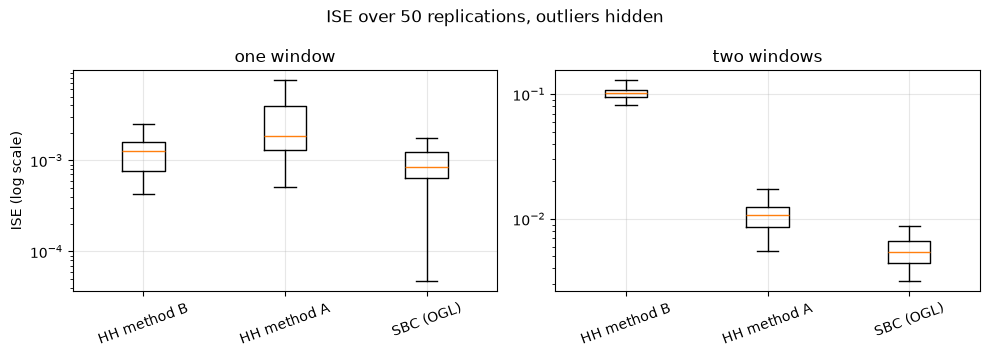

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, (name, per_method) in zip(ax, results.items()):
    a.boxplot([per_method[m] for m in METHODS], tick_labels=METHODS, showfliers=False)
    a.tick_params(axis="x", rotation=20)
    a.set_yscale("log")
    a.set_title(name)
ax[0].set_ylabel("ISE (log scale)")
plt.suptitle(f"ISE over {n_rep} replications, outliers hidden")
plt.tight_layout(); plt.show()

Method A's wild draws are worth looking at rather than hiding, since they are the one way it
fails, and the diagnostic that identifies them is available at fit time.

In [9]:
for name, per_method in results.items():
    v = per_method["HH method A"]
    bad = np.flatnonzero(v > 100 * np.median(v))
    print(f"{name}: {len(bad)} wild draw(s) of {n_rep}")
    for r in bad:
        dg = diagnostics[name][r]
        print(f"  seed {r}: ISE {v[r]:.3g}, u_hat {dg['u_hat']:.4f}, "
              f"m_hat {dg['m_hat']}")
    ok = [diagnostics[name][r] for r in range(n_rep) if r not in set(bad)]
    print(f"  median over the other draws: u_hat "
          f"{np.median([d['u_hat'] for d in ok]):.4f}, "
          f"m_hat {int(np.median([d['m_hat'] for d in ok]))}")

one window: 1 wild draw(s) of 50
  seed 42: ISE 1.87e+16, u_hat 0.9700, m_hat 9
  median over the other draws: u_hat 0.8233, m_hat 2
two windows: 0 wild draw(s) of 50
  median over the other draws: u_hat 0.2000, m_hat 8


The single wild draw is the failure the paper describes. On that seed method A truncated at
$\hat u = 0.97$, leaving ten grid points, and BIC then chose $m = 9$ components to fit on
them against a median of $2$ everywhere else. Nine is the most that sub-grid can support, so
the refit keeps every component it has, down to truncated eigenvalues at the level of numerical
noise, and it is that near-singular basis which produces an ISE of $10^{16}$. Both symptoms are
visible in the fitted object, so this is diagnosable rather than silent.

We can see that the group lasso has the lowest median ISE on both targets. On the two windows
the ordering is unambiguous and every gap is decisive: the truncation methods can place only
one boundary, so whichever region they keep, the other is discarded or dragged in along with
the null gap between them.

The single window is the case Hall & Hooker's model describes exactly, and the truncation
methods still do not win it. The group lasso is ahead of method B on 62% of draws, which the
signed-rank test does not separate from a tie ($p = 0.088$), and it beats method A outright.
What the truncation model buys on its own ground is not accuracy but an explicit $\hat u$
with a sampling distribution attached, which is a different thing to want.

Method B also beats method A here, reversing the ordering that `truncFLR_methodA.ipynb` finds
on an indicator window. The quartiles say why: method A refits on $[0, \theta]$ at every
candidate, and on a smooth target that extra flexibility costs variance, spreading its ISE
over $[0.0013, 0.0039]$ against method B's $[0.0008, 0.0016]$.

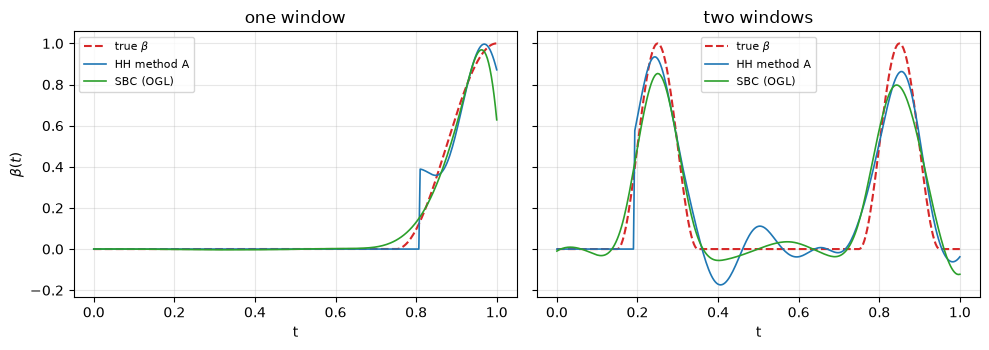

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, (name, beta_fn) in zip(ax, [("one window", beta_window),
                                   ("two windows", beta_two_windows)]):
    d = HH_dgp.sim_dataset(n=200, n_grid=len(grid), u=0.0, v=1.0, snr=20.0,
                           beta_fn=beta_fn, rng=0)
    X, Y, beta_true = d["X"], d["Y"], d["b"]
    fits = {
        "HH method A": HH_A.fit_mirror(X, Y, grid, lambdas)["b_hat"],
        "SBC (OGL)": SBC.cv_fit(X, Y - Y.mean(), grid, n_basis=15, n_folds=10,
                                n_lambda=30, rng=0)["beta"],
    }
    a.plot(grid, beta_true, color="C3", ls="--", lw=1.5, label=r"true $\beta$")
    for (label, b), colour in zip(fits.items(), ["C0", "C2"]):
        a.plot(grid, b, color=colour, lw=1.2, label=label)
    a.set_xlabel("t"); a.set_title(name); a.legend(fontsize=8)
ax[0].set_ylabel(r"$\beta(t)$")
plt.tight_layout(); plt.show()

## Summary

Each method pays for its own assumption, but not in the direction the setup suggests.
`truncFLR` estimates one number and commits to it, which should use the data efficiently when
a single interval is genuinely the whole story. On this design it does not: the group lasso
matches method B on the single window and beats both truncation methods on the pair, without
being told that a null set exists at all.

What the truncation model has that the penalty does not is an explicit $\hat u$. The group
lasso reports a null set, but it reports it as whichever basis groups the penalty happened to
switch off, with no standard error and no sampling distribution. When the question is
*where does the signal start*, rather than *what is the coefficient function*, that is the
answer worth having, and it is the reason to keep both.

The practical reading is to fit the group lasso first, since it costs little and assumes
least, and look at the shape of the null set it returns. If it is one interval, refit with the
truncation model to get a boundary you can attach uncertainty to; if it is not, the truncation
model was never going to describe it.